# Neural Style Transfer · 사진에 그림 스타일 입히기

내 사진의 형태를 유지하면서 다른 그림의 색감과 질감을 입히는 실습입니다.

## 실행 방법
- 오른쪽 위 커널에서 **CT denoising (.venv)**를 선택합니다.
- **01부터 23까지**, 각 마크다운 제목 바로 아래의 코드 셀을 위에서 아래로 실행합니다.
- 제목의 번호는 **설명 단계 번호**입니다. 코드 왼쪽의 `[6]`, `[12]` 같은 숫자는 실행 횟수이므로 단계 번호와 다릅니다.
- 내 사진을 바꾸는 곳: **07. 내용 이미지 경로 지정**.
- 사진만 미리 확인하기: **07 → 08 → 09**.
- 바꾼 사진으로 스타일 변환하기: 07~09에서 확인한 뒤 **11부터 23까지 순서대로 다시 실행**합니다. VGG 모델과 스타일 이미지는 먼저 준비되어 있어야 합니다.


## 01. 실행 환경 확인

아래 코드에서 Python 경로가 이 프로젝트의 `.venv/bin/python`인지 확인합니다. 패키지 설치 명령은 주석에 적혀 있으며, 필요한 경우 터미널에서 실행합니다.


In [1]:
# 처음 한 번, 프로젝트 폴더의 터미널에서 실행하세요:
# uv pip install --python .venv torch torchvision pillow matplotlib numpy ipykernel
# 노트북 오른쪽 위 커널은 이 프로젝트의 .venv/bin/python을 선택하세요.
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)

Python: /Users/tak-e/develop/projects/ct-denoising/.venv/bin/python
PyTorch: 2.14.1


## 02. 필요한 패키지 확인

현재 커널에서 torchvision, Pillow, NumPy, matplotlib을 가져오고 버전을 출력합니다. 여기까지 오류 없이 실행되는지 먼저 확인하세요.


In [2]:
# 설치는 터미널에서 합니다. 여기서는 현재 커널의 패키지를 확인합니다.
import torchvision
import PIL
import numpy as np
import matplotlib

print("torchvision:", torchvision.__version__)
print("Pillow:", PIL.__version__)
print("NumPy:", np.__version__)
print("matplotlib:", matplotlib.__version__)

torchvision: 0.29.1
Pillow: 12.3.0
NumPy: 2.5.3
matplotlib: 3.11.2


## 03. VGG 모델 불러오기

사진의 특징을 읽는 사전학습 VGG19를 불러옵니다. 처음 실행하면 약 548 MB의 가중치를 내려받으므로 시간이 걸릴 수 있습니다.


In [3]:
from torchvision import models

# 처음 실행할 때 ImageNet 사전학습 가중치(약 548 MB)를 내려받습니다.
vgg = models.vgg19(weights=models.VGG19_Weights.DEFAULT).features.eval()

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /Users/tak-e/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100.0%


## 04. 계산 장치 선택

사용 가능한 CUDA 또는 Mac의 MPS가 있으면 GPU를 사용하고, 없으면 CPU를 사용합니다. 출력된 `계산 장치`를 확인하세요.


In [4]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # Apple Silicon의 GPU
else:
    device = torch.device("cpu")

vgg.to(device)
print("계산 장치:", device)

계산 장치: mps


## 05. VGG 가중치 고정

VGG의 가중치는 바꾸지 않습니다. 이 실습에서는 모델 대신 결과 이미지의 픽셀을 조정합니다.


In [5]:
for param in vgg.parameters():
    param.requires_grad_(False)

## 06. 스타일 이미지 경로 준비

붓터치와 색감의 기준이 되는 그림을 준비합니다. 현재 예제는 `delaunay.jpg`이며 파일이 없으면 다운로드합니다.


In [6]:
from pathlib import Path
from urllib.request import urlretrieve

# wget 없이 Python으로 예제 이미지를 받습니다. 이미 있으면 다시 받지 않습니다.
style_path = Path("delaunay.jpg")
if not style_path.is_file():
    urlretrieve(
        "https://raw.githubusercontent.com/udacity/deep-learning-v2-pytorch/master/style-transfer/images/delaunay.jpg",
        style_path,
    )
print("스타일 이미지:", style_path.resolve())

스타일 이미지: /Users/tak-e/develop/projects/ct-denoising/delaunay.jpg


## 07. 내용 이미지 경로 지정

**내 사진을 바꾸려면 바로 아래 코드의 `content_path = Path(...)` 안을 수정하세요.** 현재는 바탕화면의 `person-portrait-square-color.png`를 가리킵니다. 이 코드는 사진을 표시하지 않고, 사용할 파일의 위치를 정합니다.


In [ ]:
from pathlib import Path

# 이미 컴퓨터에 있는 사진은 다운로드하지 않고, 파일 경로를 직접 지정합니다.
content_path = Path(
    "/Users/tak-e/Desktop/에듀플러스 포트폴리오 합격사례/person-portrait-square-color.png"
)
if not content_path.is_file():
    raise FileNotFoundError(f"내용 이미지가 없습니다: {content_path}")
print("내용 이미지:", content_path)


## 08. 두 이미지 파일 읽기

07에서 정한 사진과 06에서 정한 그림을 실제로 읽어 `content_img`, `style_img`에 담습니다. 둘 다 RGB 3채널로 맞춥니다. 사진 경로를 바꿨다면 이 코드도 다시 실행하세요.


In [8]:
from PIL import Image

# PNG에 투명도 채널이 있어도 VGG 입력에 맞춰 RGB 3채널로 통일합니다.
content_img = Image.open(content_path).convert("RGB")
style_img = Image.open(style_path).convert("RGB")

## 09. 내용 이미지 미리 보기

**내 사진이 맞게 선택됐는지 여기서 확인합니다.** 07 → 08 → 09 순서로 실행하면 지정한 사진이 표시됩니다.


Matplotlib is building the font cache; this may take a moment.


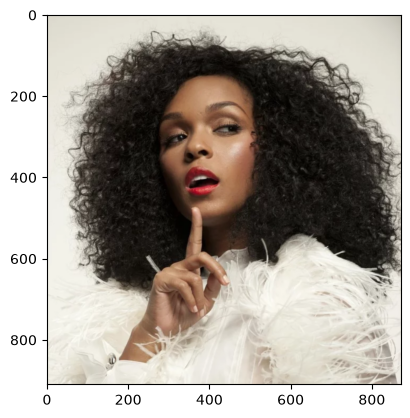

In [9]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.imshow(content_img)
plt.grid(False)
plt.show()

## 10. 스타일 이미지 미리 보기

입힐 색감과 질감의 기준이 되는 그림을 표시합니다.


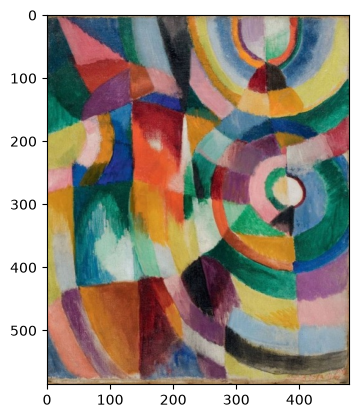

In [10]:
plt.imshow(style_img)
plt.grid(False)
plt.show()

## 11. 이미지를 모델 입력 Tensor로 변환

두 이미지를 400×400으로 맞추고 정규화한 뒤, `(1, 3, 400, 400)` Tensor로 바꿉니다. 1은 이미지 수, 3은 RGB 채널 수입니다. **사진을 바꿨다면 여기부터 아래도 순서대로 다시 실행해야 합니다.**


In [11]:
from torchvision import transforms
img_transform = transforms.Compose([transforms.Resize((400, 400)),
                transforms.ToTensor(),
                transforms.Normalize((0.485,0.456, 0.406),(0.229,0.224, 0.225))])

content = img_transform(content_img)[:3,:,:].unsqueeze(0).to(device)
style = img_transform(style_img)[:3,:,:].unsqueeze(0).to(device)  

## 12. VGG 구조 살펴보기

VGG의 층 구성을 출력합니다. 다음 단계에서 각 층의 번호를 이용해 특징을 꺼냅니다.


In [12]:
print(vgg)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (17): ReLU(inplace=True)
  (18): MaxPoo

## 13. 특징을 꺼낼 층 지정

VGG의 층 번호와 `conv1_1` 같은 이름을 연결합니다. 내용과 스타일 비교에 사용할 특징의 위치를 정합니다.


In [13]:
feature_layers = {'0': 'conv1_1',
          '5': 'conv2_1', 
          '10': 'conv3_1', 
          '19': 'conv4_1',
          '21': 'conv4_2', 
          '28': 'conv5_1'}

## 14. 내용 이미지의 특징 계산

사진을 VGG에 통과시켜 장면과 형태를 비교할 특징을 저장합니다.


In [14]:
content_features = {}
img = content # copy of content image
for name, layer in vgg._modules.items():
 img = layer(img)
 if name in feature_layers:
    content_features[feature_layers[name]] = img

## 15. 스타일 이미지의 특징 계산

스타일 그림을 VGG에 통과시켜 색감과 질감을 비교할 특징을 저장합니다.


In [15]:
style_features = {}
img = style # copy of content image
for name, layer in vgg._modules.items():
 img = layer(img)
 if name in feature_layers:
    style_features[feature_layers[name]] = img

## 16. 특징 추출 함수 정의

`get_features`는 이미지와 모델을 받아 선택한 층의 특징을 돌려줍니다. 아래 반복 계산에서 이 함수를 재사용합니다.


In [16]:
# a general function to exrtract the features
def get_features(image, model, layers=None):
    if layers is None:
        layers = {'0': 'conv1_1',
                  '5': 'conv2_1', 
                  '10': 'conv3_1', 
                  '19': 'conv4_1',
                  '21': 'conv4_2', 
                  '28': 'conv5_1'}
    features = {}
    x = image
    for name, layer in model._modules.items():
        x = layer(x)
        if name in layers:
            features[layers[name]] = x
            
    return features

## 17. Gram 행렬 함수 정의

특징 채널들이 함께 나타나는 정도를 계산합니다. 스타일의 질감을 비교할 때 사용할 함수입니다.


In [17]:
def grammatrix(tensor):
    n, d, h, w = tensor.size()
    tensor = tensor.view(d, h * w)
    grammat = torch.mm(tensor, tensor.t())
    return grammat

## 18. 스타일의 Gram 행렬 계산

기준 그림의 스타일 정보를 미리 계산해 둡니다. 결과 이미지의 스타일을 이 값과 비교합니다.


In [18]:
style_gram_matrix = {layer: grammatrix(style_features[layer]) for layer in style_features}

## 19. 결과 이미지의 시작점 만들기

내용 사진을 복사해 `target`을 만듭니다. 이후 최적화에서 바뀌는 대상은 이 이미지입니다.


In [19]:
target = content.clone().requires_grad_(True).to(device)

## 20. 내용과 스타일의 비중 설정

`content_weight`는 원래 사진의 내용을 유지하는 비중, `style_weight`는 그림의 스타일을 따라가는 비중입니다.


In [20]:
style_weights = {'conv1_1': 1.,
                 'conv2_1': 0.75,
                 'conv3_1': 0.2,
                 'conv4_1': 0.2,
                 'conv5_1': 0.2}

content_weight = 1  # this is alpha in the final loss
style_weight = 1e6  # this is beta in the final loss

## 21. Tensor를 표시용 이미지로 바꾸는 함수

정규화된 Tensor를 화면에 보이는 RGB 이미지로 되돌리는 `im_convert`를 정의합니다.


In [21]:
def im_convert(tensor):
    """ Display a tensor as an image. """
    
    image = tensor.to("cpu").clone().detach()
    image = image.numpy().squeeze()
    image = image.transpose(1,2,0)
    image = image * np.array((0.229, 0.224, 0.225)) + np.array((0.485, 0.456, 0.406))
    image = image.clip(0, 1)

    return image

## 22. 스타일 변환 실행

**시간이 걸리는 단계입니다.** 현재는 2,000회 반복하며, 400회마다 중간 결과를 표시합니다. 처음에는 `steps`를 작게 바꿔 실행 흐름을 확인해도 됩니다. 결과 이미지를 VGG에 넣고 손실을 계산한 뒤, 픽셀을 조금씩 조정합니다.


Total loss:  7953694.0


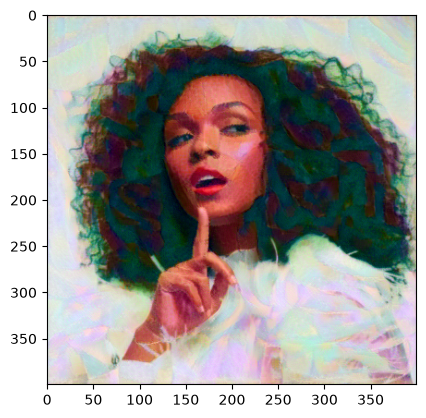

Total loss:  3069721.0


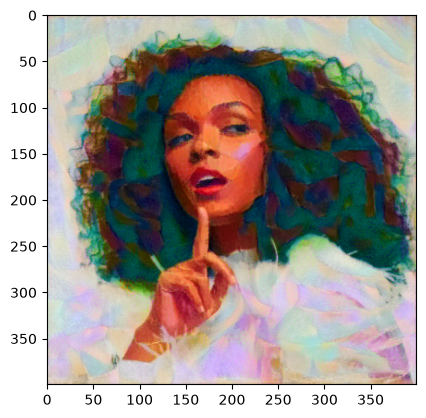

Total loss:  1517223.0


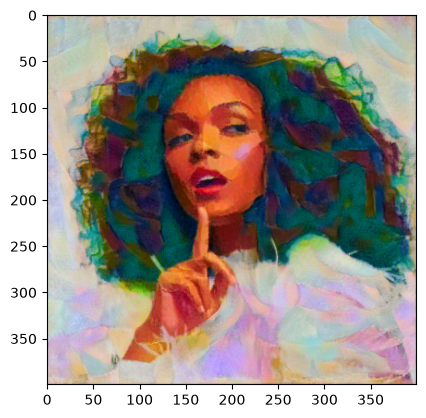

Total loss:  774923.1875


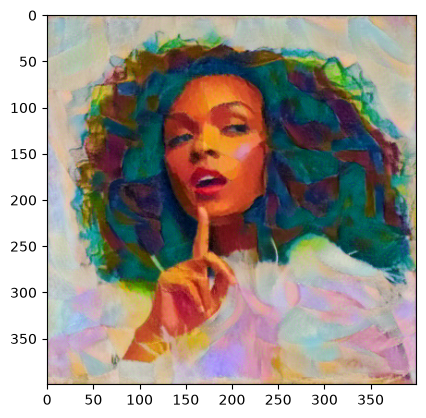

Total loss:  423587.75


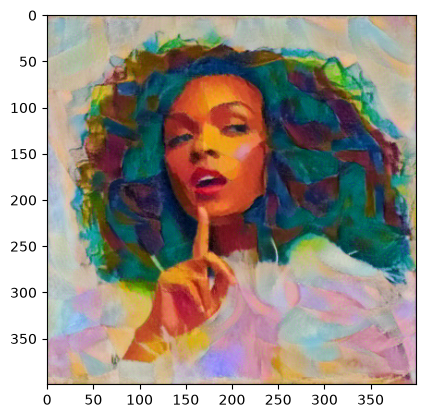

In [22]:
from torch import optim
import numpy as np

show_img = 400

optimizer = optim.Adam([target], lr=0.003)
steps = 2000  

for ii in range(1, steps+1):
    target_features = get_features(target, vgg)
    content_loss = torch.mean((target_features['conv4_2'] - content_features['conv4_2'])**2)
    style_loss = 0
    for layer in style_weights:
        target_feature = target_features[layer]
        target_gram = grammatrix(target_feature)
        _, d, h, w = target_feature.shape
        style_gram = style_gram_matrix[layer]
        layer_style_loss = style_weights[layer] * torch.mean((target_gram - style_gram)**2)
        style_loss += layer_style_loss / (d * h * w)
        
    total_loss = content_weight * content_loss + style_weight * style_loss
    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()
    

    if  ii % show_img == 0:
        print('Total loss: ', total_loss.item())
        plt.imshow(im_convert(target))
        plt.show()

## 23. 원본 사진과 최종 결과 비교

왼쪽에는 내용 사진, 오른쪽에는 스타일 변환 결과를 표시합니다. 22 실행을 마친 뒤 확인하세요.


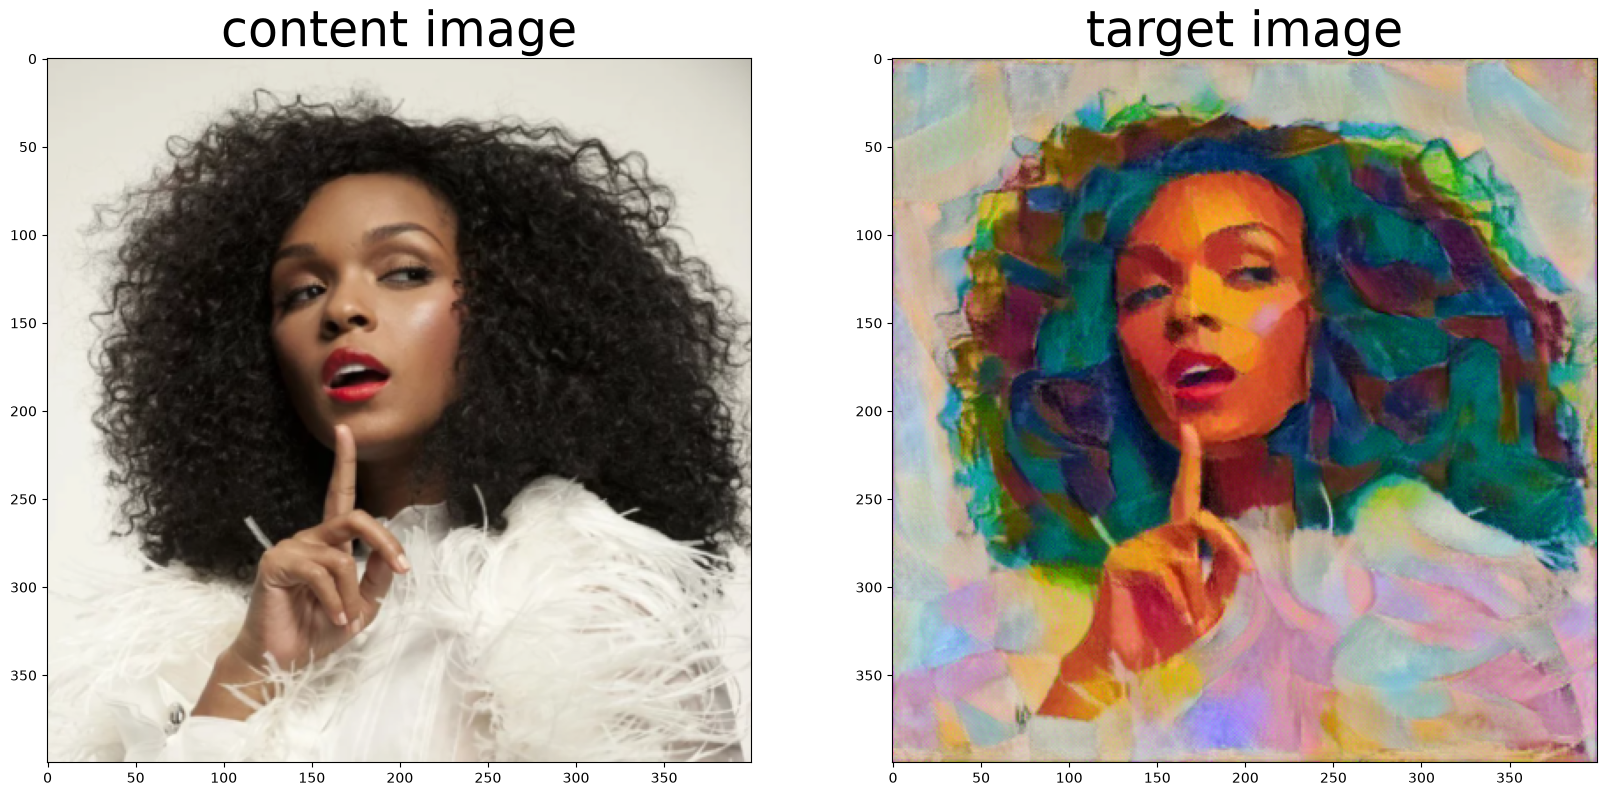

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
ax1.grid(False)
ax2.grid(False)
ax1.set_title('content image', fontsize="35", color="black")
ax2.set_title('target image', fontsize="35", color="black")
ax1.imshow(im_convert(content))
ax2.imshow(im_convert(target))
plt.show()